# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Студент: **Ширинкин Александр Александрович**. Группа: **3381**. Вариант **19**.

## Цель работы

Изучить линейные дискретные системы и ДПФ периодических и конечных последовательностей.

## Основные теоретические положения

Для звена второго порядка при нулевых начальных условиях:

$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}},\qquad
y[n]=\sum_m x[m]h[n-m].$$

Нули и полюсы — корни числителя и знаменателя. Причинное звено устойчиво,
если все полюсы лежат внутри единичной окружности.
АЧХ равна $|H(e^{j\hat\omega})|$, ФЧХ — $\arg H(e^{j\hat\omega})$,
где $\hat\omega=2\pi f/f_s$.

ДПФ и обратное преобразование:

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad
x[n]=\frac1N\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$

Для периодической последовательности $C[k]=X[k]/N$.
Используется двусторонний спектр: каждая линия косинуса амплитуды $A$ имеет высоту $A/2$.
Равенство Парсеваля:

$$\sum_n|x[n]|^2=\frac1N\sum_k|X[k]|^2.$$

## Постановка задачи

Исследовать импульсную характеристику и реакцию звена, нули и полюсы, АЧХ и ФЧХ.
Выполнить ДПФ суммы двух гармоник, восстановить сигнал и проверить равенство Парсеваля.

### Исходные данные

Часть 1:

$$b=(0.88,\ 1.161952,\ 1.408),\quad a=(1,\ -1.2528,\ 0.754),$$
$$N_1=29,\qquad N_2=39,\qquad f_{s,1}=19000\ \mathrm{Hz}.$$

Часть 2:

$$N=64,\quad f_{s,2}=10000\ \mathrm{Hz},\quad T=10^{-4}\ \mathrm{s},$$
$$A_1=1.19,\quad A_2=2.38,\quad f_1=1250\ \mathrm{Hz},\quad f_2=1875\ \mathrm{Hz}.$$

## Выполнение работы

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (11, 3.6), 'figure.dpi': 120,
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.grid': True, 'grid.alpha': 0.25,
    'axes.spines.top': False, 'axes.spines.right': False,
})
np.set_printoptions(precision=9, suppress=True)

variant = 19
b0 = 0.5 + 0.02 * variant
b = np.array([
    b0,
    b0 * (-1)**(variant + 1) * (0.9822 + 0.0178 * variant),
    b0 * (0.8 + 0.2 * (variant % 5)),
])
a = np.array([1.0, (-1)**variant * (0.7778 + 0.025 * variant),
              0.64 + 0.006 * variant])
N1, N2 = variant % 10 + 20, variant % 10 + 30
fs1 = 1000 * variant

N = 64
fs2 = 2000 * (variant % 5 + 1)
T = 1 / fs2
A1, A2 = 1 + 0.01 * variant, 2 * (1 + 0.01 * variant)
f1, f2 = fs2 / 8, 1.5 * fs2 / 8
phi1, phi2 = np.pi / 4, np.pi / 8

print(f'Вариант: {variant}; b = {b}; a = {a}')
print(f'Часть 1: N1 = {N1}, N2 = {N2}, fs1 = {fs1} Гц')
print(f'Часть 2: N = {N}, fs2 = {fs2} Гц, T = {T} с')
print(f'A1 = {A1}; A2 = {A2}; f1 = {f1} Гц; f2 = {f2} Гц')


def response(x, b, a):
    x = np.asarray(x, dtype=float)
    y = np.zeros_like(x)
    for n in range(len(x)):
        direct = sum(b[i] * x[n-i] for i in range(len(b)) if n >= i)
        feedback = sum(a[i] * y[n-i] for i in range(1, len(a)) if n >= i)
        y[n] = (direct - feedback) / a[0]
    return y


def impulse_response(length):
    delta = np.zeros(length)
    delta[0] = 1
    return response(delta, b, a)


def stem(ax, x, y, color='C0', label=None):
    marker, lines, baseline = ax.stem(x, y, basefmt=' ')
    plt.setp(marker, color=color, markersize=3)
    plt.setp(lines, color=color, linewidth=1)
    if label:
        marker.set_label(label)
    ax.axhline(0, color='0.5', linewidth=0.6)


def table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))

Вариант: 19; b = [0.88     1.161952 1.408   ]; a = [ 1.     -1.2528  0.754 ]
Часть 1: N1 = 29, N2 = 39, fs1 = 19000 Гц
Часть 2: N = 64, fs2 = 10000 Гц, T = 0.0001 с
A1 = 1.19; A2 = 2.38; f1 = 1250.0 Гц; f2 = 1875.0 Гц


### Часть 1.1. Импульсная характеристика

$$H(z)=\frac{0.88+1.161952z^{-1}+1.408z^{-2}}
{1-1.2528z^{-1}+0.754z^{-2}}.$$

При $x[n]=\delta[n]$ и нулевых начальных условиях:
$h[0]=0.88$, $h[1]=2.264416$, $h[2]=3.5813403648$.
Для $n\geq3$: $h[n]=1.2528h[n-1]-0.754h[n-2]$.

Аналитическое решение для $n\geq1$:

$$h[n]=C p_1^{n-1}+C^*p_2^{n-1},\qquad
C=\frac{h[2]-p_2h[1]}{p_1-p_2},$$
$$p_{1,2}\approx0.6264\pm j0.601351012,\qquad C\approx1.132208-j1.798375772.$$

Показаны первые 29 отсчётов. Фактическая длина $h[n]$ бесконечна;
колебания затухают, поскольку $|p_i|\approx0.8683<1$.

|p1| = 0.868331733844, arg(p1) = 0.764998658351 рад
C = (1.132208-1.7983757723382148j); 2|C| = 4.250200171191; arg(C) = -1.008915649187 рад
Ошибка аналитической формулы: 4.441e-16


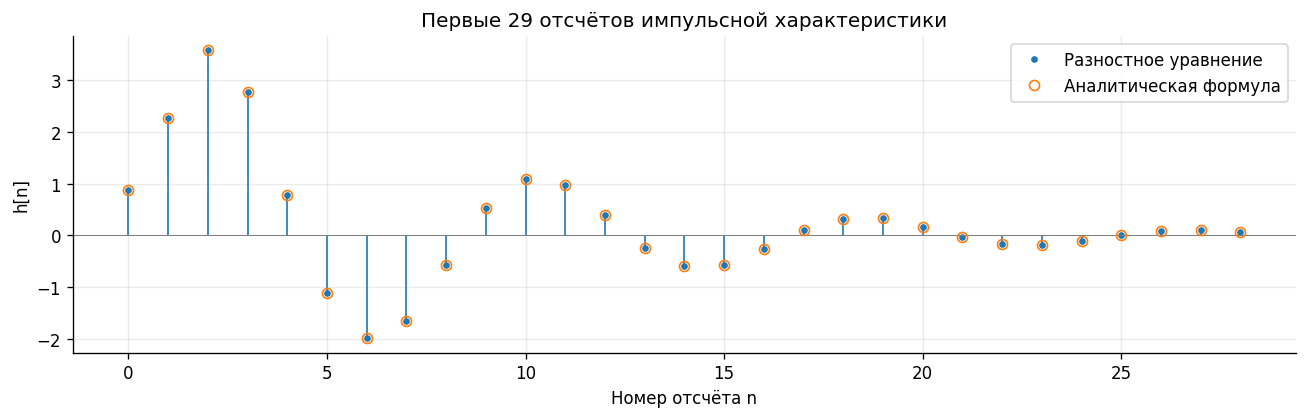

In [ ]:
h = impulse_response(N1)
poles = np.roots(a)
p1 = poles[np.argmax(poles.imag)]
p2 = p1.conjugate()
C = (h[2] - p2 * h[1]) / (p1 - p2)
n_h = np.arange(N1)
h_analytic = np.empty(N1)
h_analytic[0] = b[0]
h_analytic[1:] = (C * p1**(n_h[1:]-1) + C.conjugate() * p2**(n_h[1:]-1)).real
err_h = np.max(np.abs(h - h_analytic))
print(f'|p1| = {abs(p1):.12f}, arg(p1) = {np.angle(p1):.12f} рад')
print(f'C = {C}; 2|C| = {2*abs(C):.12f}; arg(C) = {np.angle(C):.12f} рад')
print(f'Ошибка аналитической формулы: {err_h:.3e}')
assert np.allclose(h, h_analytic, atol=1e-12, rtol=1e-12)

fig, ax = plt.subplots()
stem(ax, n_h, h, label='Разностное уравнение')
ax.plot(n_h, h_analytic, 'o', fillstyle='none', color='C1', markersize=6,
        label='Аналитическая формула')
ax.set(xlabel='Номер отсчёта n', ylabel='h[n]', title='Первые 29 отсчётов импульсной характеристики')
ax.legend()
fig.tight_layout()
plt.show()

### Часть 1.2. Реакция по свёртке

$$L=\lfloor N_2/2+0.5\rfloor=20,\qquad
x[n]=\begin{cases}1,&0\leq n<20,\\0,&20\leq n<39.\end{cases}$$

Для полуцелого значения $N_2/2=19.5$ принято округление вверх.
Свёртка вычисляется с первыми 29 отсчётами $h[n]$:

$$y_1[n]=\sum_{m=0}^{28}h[m]x[n-m].$$

Длина массива x: 39; число единичных отсчётов: 20
Длина массива полной свёртки: 67 = 39 + 29 - 1
Ненулевые значения свёртки: n = 0...47 (48 отсчётов)
Длина обрезанного массива y1: 39


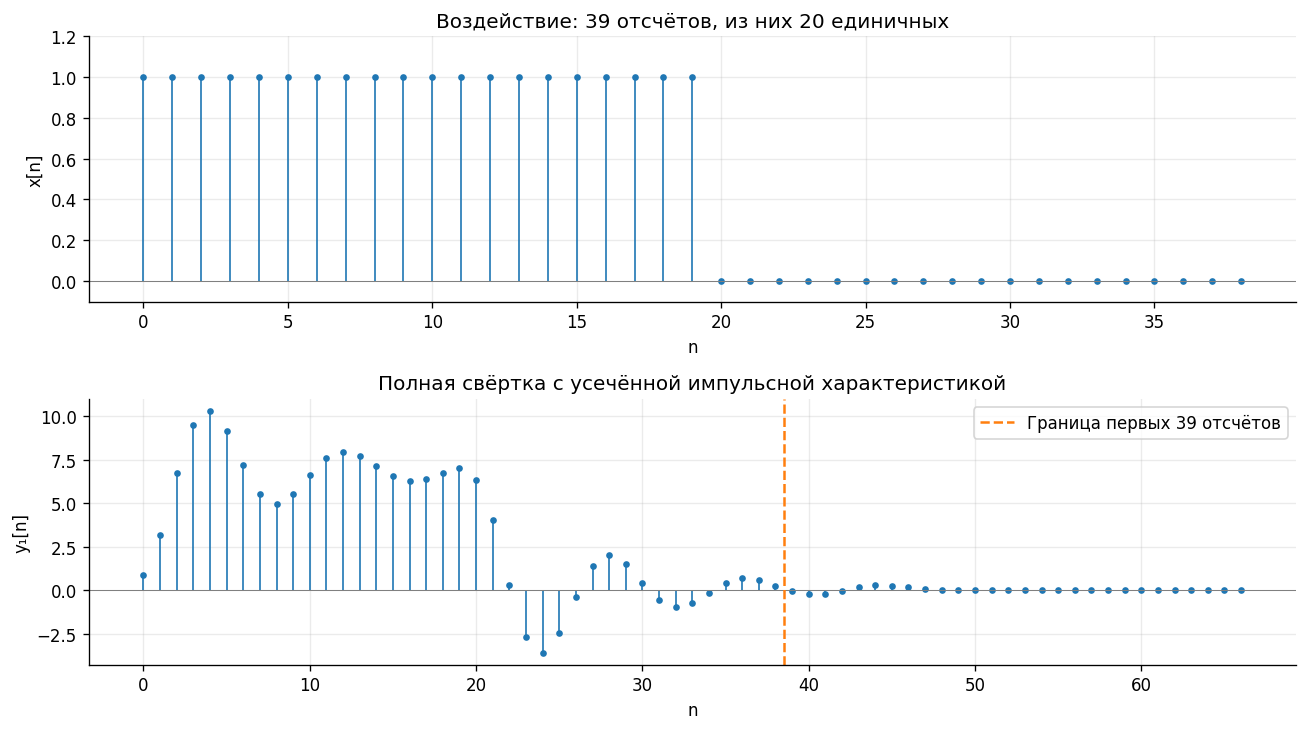

In [ ]:
pulse_length = int(np.floor(N2 / 2 + 0.5))
x_pulse = (np.arange(N2) < pulse_length).astype(float)
y1_full = np.convolve(x_pulse, h, mode='full')
y1 = y1_full[:N2]
active = np.flatnonzero(np.abs(y1_full) > 1e-12)

print(f'Длина массива x: {len(x_pulse)}; число единичных отсчётов: {pulse_length}')
print(f'Длина массива полной свёртки: {len(y1_full)} = {N2} + {N1} - 1')
print(f'Ненулевые значения свёртки: n = {active[0]}...{active[-1]} '
      f'({len(active)} отсчётов)')
print(f'Длина обрезанного массива y1: {len(y1)}')

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
stem(axes[0], np.arange(N2), x_pulse)
axes[0].set(title='Воздействие: 39 отсчётов, из них 20 единичных', xlabel='n', ylabel='x[n]', ylim=(-0.1, 1.2))
stem(axes[1], np.arange(len(y1_full)), y1_full)
axes[1].axvline(N2 - 0.5, color='C1', linestyle='--', label='Граница первых 39 отсчётов')
axes[1].set(title='Полная свёртка с усечённой импульсной характеристикой', xlabel='n', ylabel='y₁[n]')
axes[1].legend()
fig.tight_layout()
plt.show()

Входной массив содержит 39 отсчётов, ненулевая часть импульса — 20 (1.053 мс).
Длина массива свёртки равна $39+29-1=67$; ненулевой участок — $n=0,\ldots,47$.
Первые 39 значений используются для сравнения с рекурсивным расчётом
в одном окне наблюдения. Реакция исходного звена продолжается и за его пределами.

### Часть 1.3. Реакция по разностному уравнению

$$y_2[n]=0.88x[n]+1.161952x[n-1]+1.408x[n-2]
+1.2528y_2[n-1]-0.754y_2[n-2],$$
$$x[n]=y_2[n]=0\quad(n<0).$$

Максимальное отличие y1 и y2 на всей записи: 0.153809433
Отличие на первых 29 отсчётах: 2.665e-15
Отличие при использовании h длины 39: 2.665e-15


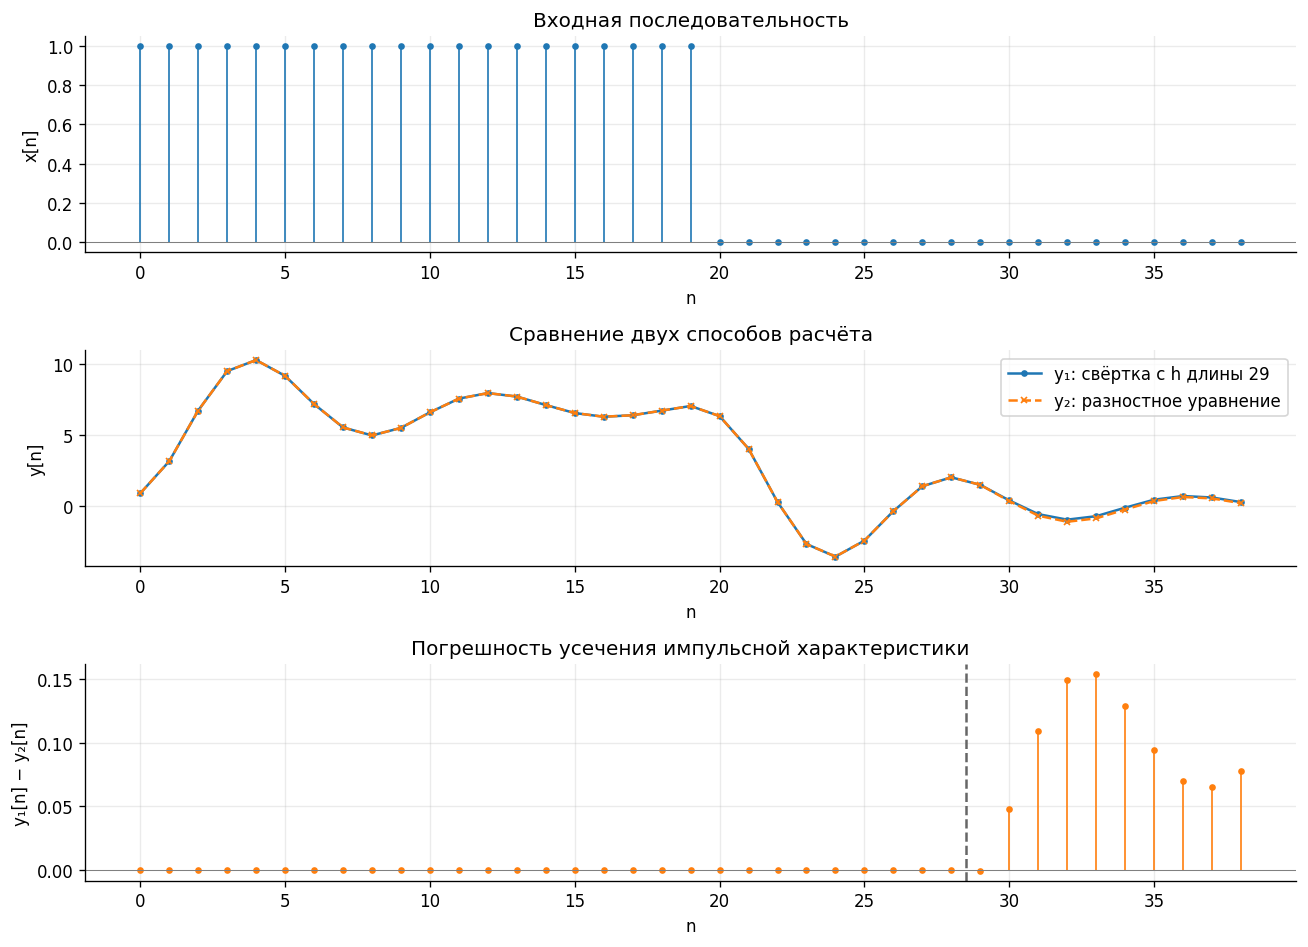

In [ ]:
y2 = response(x_pulse, b, a)
h39 = impulse_response(N2)
y_exact_conv = np.convolve(x_pulse, h39)[:N2]
err_trunc = np.max(np.abs(y1 - y2))
err_conv = np.max(np.abs(y_exact_conv - y2))
print(f'Максимальное отличие y1 и y2 на всей записи: {err_trunc:.9f}')
print(f'Отличие на первых {N1} отсчётах: {np.max(np.abs(y1[:N1]-y2[:N1])):.3e}')
print(f'Отличие при использовании h длины 39: {err_conv:.3e}')
assert np.allclose(y_exact_conv, y2, atol=1e-12, rtol=1e-12)
assert np.allclose(y1[:N1], y2[:N1], atol=1e-12, rtol=1e-12)

fig, axes = plt.subplots(3, 1, figsize=(11, 8))
stem(axes[0], np.arange(N2), x_pulse)
axes[0].set(xlabel='n', ylabel='x[n]', title='Входная последовательность')
axes[1].plot(y1, 'o-', markersize=3, label='y₁: свёртка с h длины 29')
axes[1].plot(y2, 'x--', markersize=4, label='y₂: разностное уравнение')
axes[1].set(xlabel='n', ylabel='y[n]', title='Сравнение двух способов расчёта')
axes[1].legend()
stem(axes[2], np.arange(N2), y1-y2, color='C1')
axes[2].axvline(N1 - 0.5, color='0.4', linestyle='--')
axes[2].set(xlabel='n', ylabel='y₁[n] − y₂[n]', title='Погрешность усечения импульсной характеристики')
fig.tight_layout()
plt.show()

Вычисленные массивы $x$ и $y_2$ имеют длину 39. При $n=0,\ldots,28$
реакции совпадают; далее появляется ошибка усечения $h[n]$.
Максимальное отличие равно 0.153809433.
Свёртка с 39 отсчётами $h[n]$ совпадает с рекурсивным расчётом на всём окне
с погрешностью около $2.7\cdot10^{-15}$.

### Часть 1.4. Нули и полюсы

**1. Найти корни числителя и знаменателя:**

$$0.88z^2+1.161952z+1.408=0,\qquad z^2-1.2528z+0.754=0.$$

Нули и полюсы:

$$z_{1,2}\approx-0.6602\pm j1.078951324,$$
$$p_{1,2}\approx0.6264\pm j0.601351012.$$

**2. Найти модули корней.**

Модуль комплексного числа равен корню из суммы квадратов его вещественной и мнимой частей:

$$r_z=\sqrt{(-0.6602)^2+1.078951324^2}\approx1.264911064,$$
$$r_p=\sqrt{0.6264^2+0.601351012^2}\approx0.868331734.$$

**3. Найти углы корней.**

Для корней с положительной мнимой частью нуль расположен во второй четверти,
а полюс — в первой. Поэтому:

$$\theta_z=\pi-\arctan\left(\frac{1.078951324}{0.6602}\right)
\approx0.674789251\pi,$$

$$\theta_p=\arctan\left(\frac{0.601351012}{0.6264}\right)
\approx0.243506636\pi.$$

У сопряжённых корней углы имеют противоположные знаки.

**4. Записать корни в показательной форме:**

$$z_{1,2}\approx1.264911064e^{\pm j0.674789251\pi},$$
$$p_{1,2}\approx0.868331734e^{\pm j0.243506636\pi}.$$


С округлением корней:

$$H(z)\approx0.88\,
\frac{(1-1.264911064e^{j0.674789251\pi}z^{-1})(1-1.264911064e^{-j0.674789251\pi}z^{-1})}
{(1-0.868331734e^{j0.243506636\pi}z^{-1})(1-0.868331734e^{-j0.243506636\pi}z^{-1})}.$$

### Часть 1.5. Карта нулей и полюсов. Устойчивость

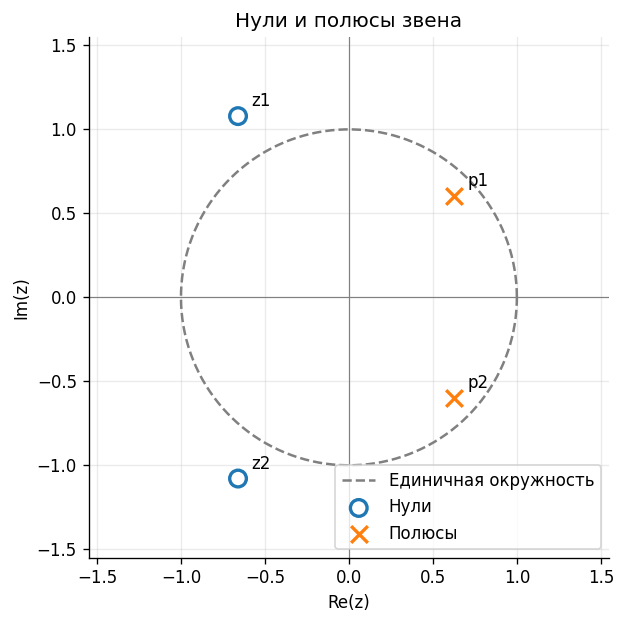

Максимальный модуль полюса: 0.868331734 < 1 — система устойчива.


In [ ]:
zeros = np.roots(b)
poles = np.roots(a)
fig, ax = plt.subplots(figsize=(6.4, 5.3))
theta = np.linspace(0, 2*np.pi, 600)
ax.plot(np.cos(theta), np.sin(theta), '--', color='0.5', label='Единичная окружность')
ax.scatter(zeros.real, zeros.imag, s=100, facecolors='none', edgecolors='C0', linewidths=2, label='Нули')
ax.scatter(poles.real, poles.imag, s=100, marker='x', color='C1', linewidths=2, label='Полюсы')
for i, q in enumerate(zeros):
    ax.annotate(f'z{i+1}', (q.real, q.imag), xytext=(8, 6), textcoords='offset points')
for i, q in enumerate(poles):
    ax.annotate(f'p{i+1}', (q.real, q.imag), xytext=(8, 6), textcoords='offset points')
ax.axhline(0, color='0.5', linewidth=0.7)
ax.axvline(0, color='0.5', linewidth=0.7)
ax.set(xlabel='Re(z)', ylabel='Im(z)', title='Нули и полюсы звена',
       xlim=(-1.55, 1.55), ylim=(-1.55, 1.55), aspect='equal')
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()
print(f'Максимальный модуль полюса: {np.max(np.abs(poles)):.9f} < 1 — система устойчива.')

Полюсы имеют модуль $0.868331734<1$: причинное звено устойчиво.
Координаты на карте совпадают с рассчитанными корнями.
Нули вне единичной окружности не нарушают устойчивость прямой системы.

### Часть 1.6. АЧХ и ФЧХ в нормированных частотах

$$H(e^{j\hat\omega})=
\frac{0.88+1.161952e^{-j\hat\omega}+1.408e^{-j2\hat\omega}}
{1-1.2528e^{-j\hat\omega}+0.754e^{-j2\hat\omega}}.$$

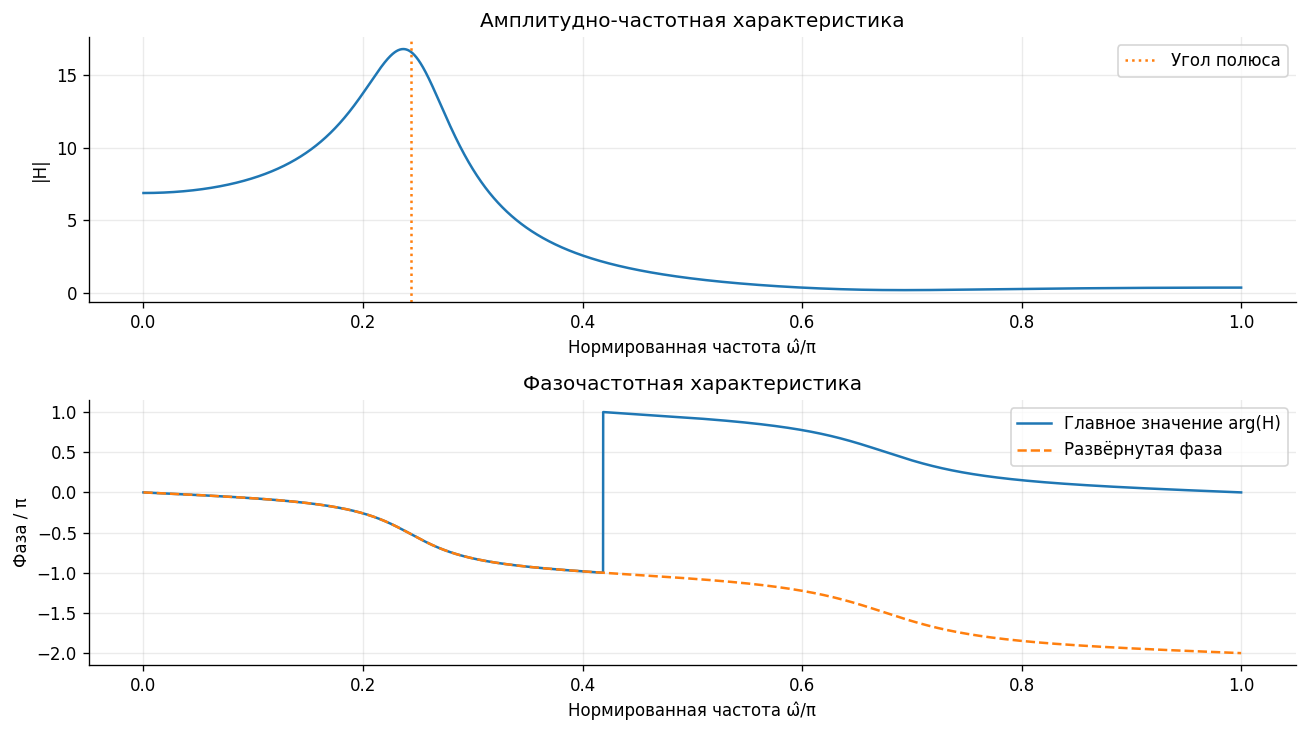

|H(0)| = 6.883383879; |H(π)| = 0.374500466
Максимум на сетке: 16.788301, ω̂/π = 0.236694
Минимум АЧХ на сетке: 0.201859193
Число внутренних переходов главной фазы через границу ±π: 1


In [ ]:
omega = np.linspace(0, np.pi, 8193)
q = np.exp(-1j * omega)
H = (b[0] + b[1]*q + b[2]*q**2) / (a[0] + a[1]*q + a[2]*q**2)
magnitude = np.abs(H)
phase = np.angle(H)
phase_unwrapped = np.unwrap(phase)
i_peak = np.argmax(magnitude)
jumps = np.flatnonzero(np.abs(np.diff(phase)) > np.pi)

fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
axes[0].plot(omega/np.pi, magnitude)
axes[0].axvline(np.angle(p1)/np.pi, color='C1', linestyle=':', label='Угол полюса')
axes[0].set(xlabel='Нормированная частота ω̂/π', ylabel='|H|', title='Амплитудно-частотная характеристика')
axes[0].legend()
axes[1].plot(omega/np.pi, phase/np.pi, label='Главное значение arg(H)')
axes[1].plot(omega/np.pi, phase_unwrapped/np.pi, '--', label='Развёрнутая фаза')
axes[1].set(xlabel='Нормированная частота ω̂/π', ylabel='Фаза / π', title='Фазочастотная характеристика')
axes[1].legend()
fig.tight_layout()
plt.show()
print(f'|H(0)| = {magnitude[0]:.9f}; |H(π)| = {magnitude[-1]:.9f}')
print(f'Максимум на сетке: {magnitude[i_peak]:.6f}, ω̂/π = {omega[i_peak]/np.pi:.6f}')
print(f'Минимум АЧХ на сетке: {magnitude.min():.9f}')
print(f'Число внутренних переходов главной фазы через границу ±π: {len(jumps)}')

Основная полоса — $[-\pi;\pi)$; показана половина $[0;\pi]$.
Полюсы около $\pm0.244\pi$ создают подъём АЧХ, нули около
$\pm0.675\pi$ — спад. Высокие частоты ослабляются сильнее низких:
$|H(0)|\approx6.8834$, $|H(\pi)|\approx0.3745$.

Около $0.419\pi$ главная фаза переходит от $-\pi$ к $+\pi$.
Этот скачок на $2\pi$ связан с отображением аргумента, а не с нулём АЧХ:
модуль здесь около 2.15. Скачка на $\pi$ и нулей АЧХ нет.

### Часть 1.7. АЧХ и ФЧХ в герцах

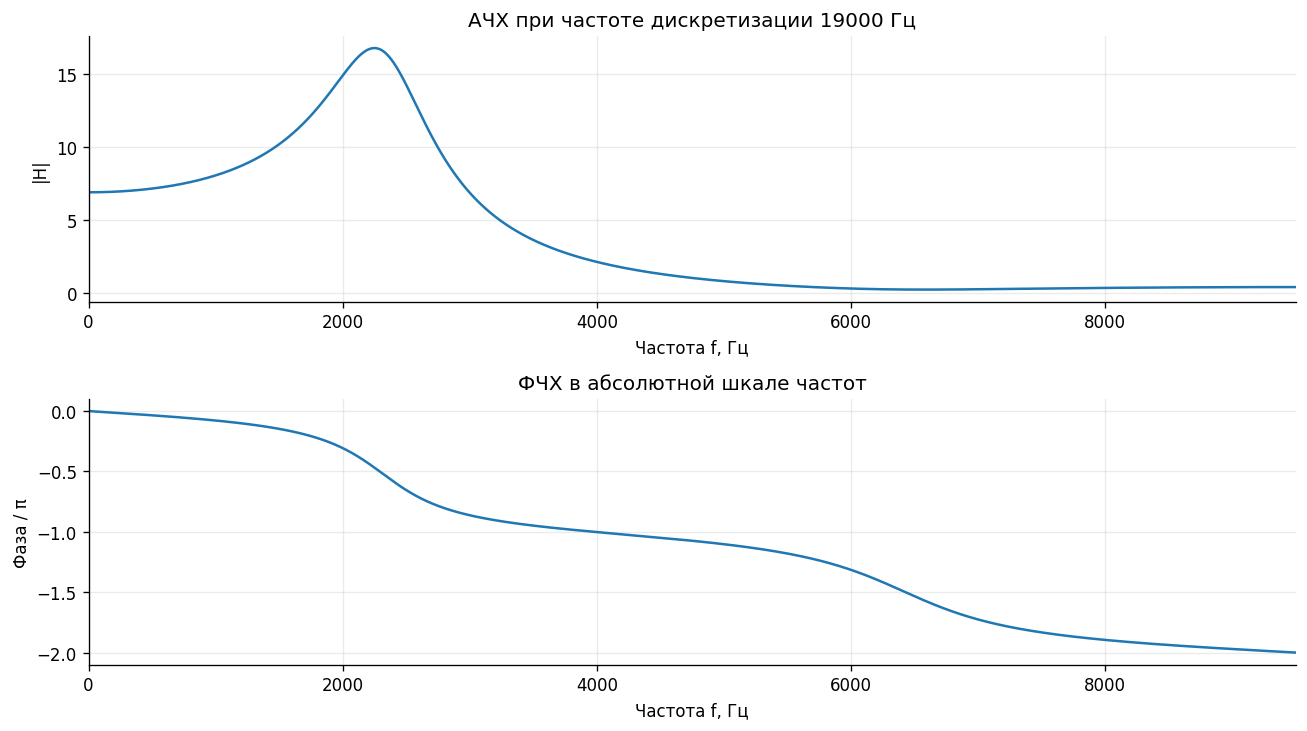

Частота максимума на сетке: 2248.596 Гц


In [ ]:
freq_hz = omega * fs1 / (2*np.pi)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
axes[0].plot(freq_hz, magnitude)
axes[0].set(xlabel='Частота f, Гц', ylabel='|H|', title='АЧХ при частоте дискретизации 19000 Гц', xlim=(0, fs1/2))
axes[1].plot(freq_hz, phase_unwrapped/np.pi)
axes[1].set(xlabel='Частота f, Гц', ylabel='Фаза / π', title='ФЧХ в абсолютной шкале частот', xlim=(0, fs1/2))
fig.tight_layout()
plt.show()
print(f'Частота максимума на сетке: {freq_hz[i_peak]:.3f} Гц')

Шкалы связаны формулой $f=\hat\omega f_{s,1}/(2\pi)$.
При $f_{s,1}=19000$ Гц основная полоса — $[-9500;9500)$ Гц,
положительная половина — $[0;9500]$ Гц. Максимум АЧХ на сетке:
16.788301 при 2248.596 Гц.

### Часть 2.1. Периодическая последовательность

$$x[n]=1.19\cos(2\pi\cdot1250nT+\pi/4)
+2.38\cos(2\pi\cdot1875nT+\pi/8),\qquad 0\leq n<64.$$

Дискретное время — $t_n=nT$, нормированное — $n=t_n/T$.
За блок укладываются 8 и 12 периодов гармоник. Минимальный общий период —
16 отсчётов (1.6 мс); блок анализа — 64 отсчёта (6.4 мс).
Последний отсчёт расположен при 6.3 мс.

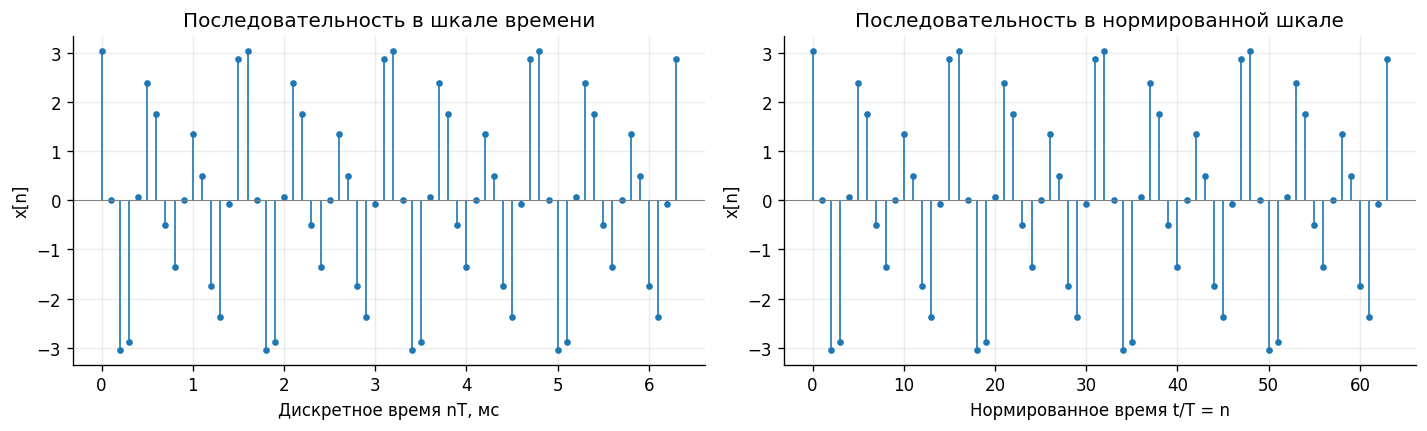

Длительность периода анализа NT: 6.400 мс
Время последнего отсчёта (N−1)T: 6.300 мс
Частотный шаг fs2/N: 156.25 Гц; номера гармоник: 8 и 12


In [ ]:
n = np.arange(N)
t_samples = n*T
x = A1*np.cos(2*np.pi*f1*t_samples + phi1) + A2*np.cos(2*np.pi*f2*t_samples + phi2)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
stem(axes[0], t_samples*1000, x)
axes[0].set(xlabel='Дискретное время nT, мс', ylabel='x[n]', title='Последовательность в шкале времени')
stem(axes[1], n, x)
axes[1].set(xlabel='Нормированное время t/T = n', ylabel='x[n]', title='Последовательность в нормированной шкале')
fig.tight_layout()
plt.show()
print(f'Длительность периода анализа NT: {N*T*1000:.3f} мс')
print(f'Время последнего отсчёта (N−1)T: {(N-1)*T*1000:.3f} мс')
print(f'Частотный шаг fs2/N: {fs2/N:.2f} Гц; номера гармоник: {f1*N/fs2:g} и {f2*N/fs2:g}')

### Часть 2.2. ДПФ и обратное преобразование

ОДПФ восстанавливает исходные отсчёты с погрешностью порядка $10^{-15}$.

Максимальная ошибка ОДПФ(ДПФ(x)): 1.351e-15
Максимальное отличие FFT от прямой формулы ДПФ: 5.381e-13
Максимальная мнимая часть ОДПФ: 7.866e-16


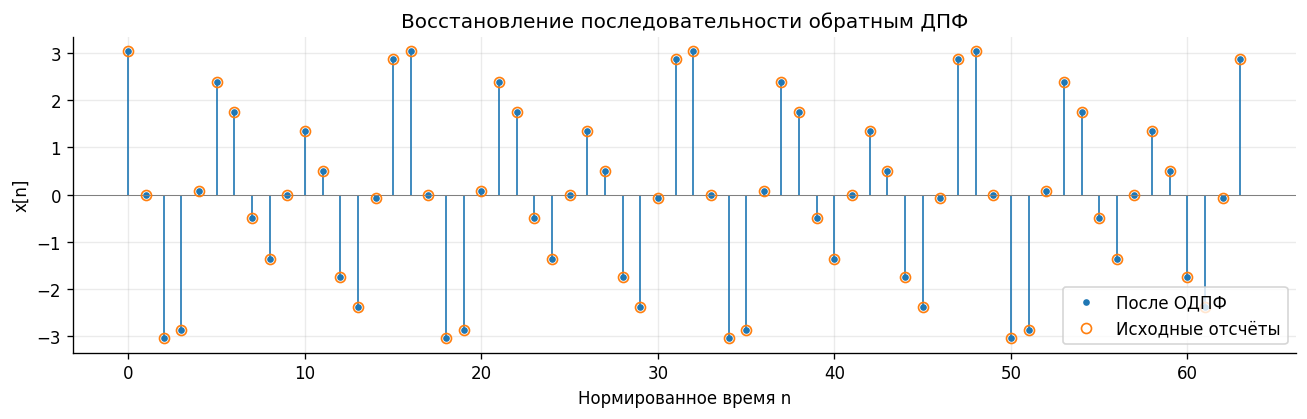

In [ ]:
X = np.fft.fft(x)
x_idft = np.fft.ifft(X)
err_idft = np.max(np.abs(x_idft-x))

# Независимая проверка ДПФ прямым суммированием по определению.
k = np.arange(N)
W = np.exp(-2j*np.pi*np.outer(k, n)/N)
X_direct = W @ x
err_dft = np.max(np.abs(X-X_direct))
print(f'Максимальная ошибка ОДПФ(ДПФ(x)): {err_idft:.3e}')
print(f'Максимальное отличие FFT от прямой формулы ДПФ: {err_dft:.3e}')
print(f'Максимальная мнимая часть ОДПФ: {np.max(np.abs(x_idft.imag)):.3e}')
assert np.allclose(x_idft, x, atol=1e-12, rtol=1e-12)
assert np.allclose(X, X_direct, atol=1e-10, rtol=1e-12)

fig, ax = plt.subplots()
stem(ax, n, x_idft.real, label='После ОДПФ')
ax.plot(n, x, 'o', color='C1', fillstyle='none', markersize=6, label='Исходные отсчёты')
ax.set(xlabel='Нормированное время n', ylabel='x[n]', title='Восстановление последовательности обратным ДПФ')
ax.legend()
fig.tight_layout()
plt.show()

### Часть 2.3. Амплитудный и фазовый спектры

$$C[k]=X[k]/64,\quad A[k]=|C[k]|,\quad\varphi[k]=\arg C[k],$$
$$\hat\omega_k=2\pi k/64,\qquad f_k=kf_{s,2}/64.$$

Используются индексы $k=-32,\ldots,31$ и двусторонний спектр.
Фазы численно нулевых коэффициентов не показываются.

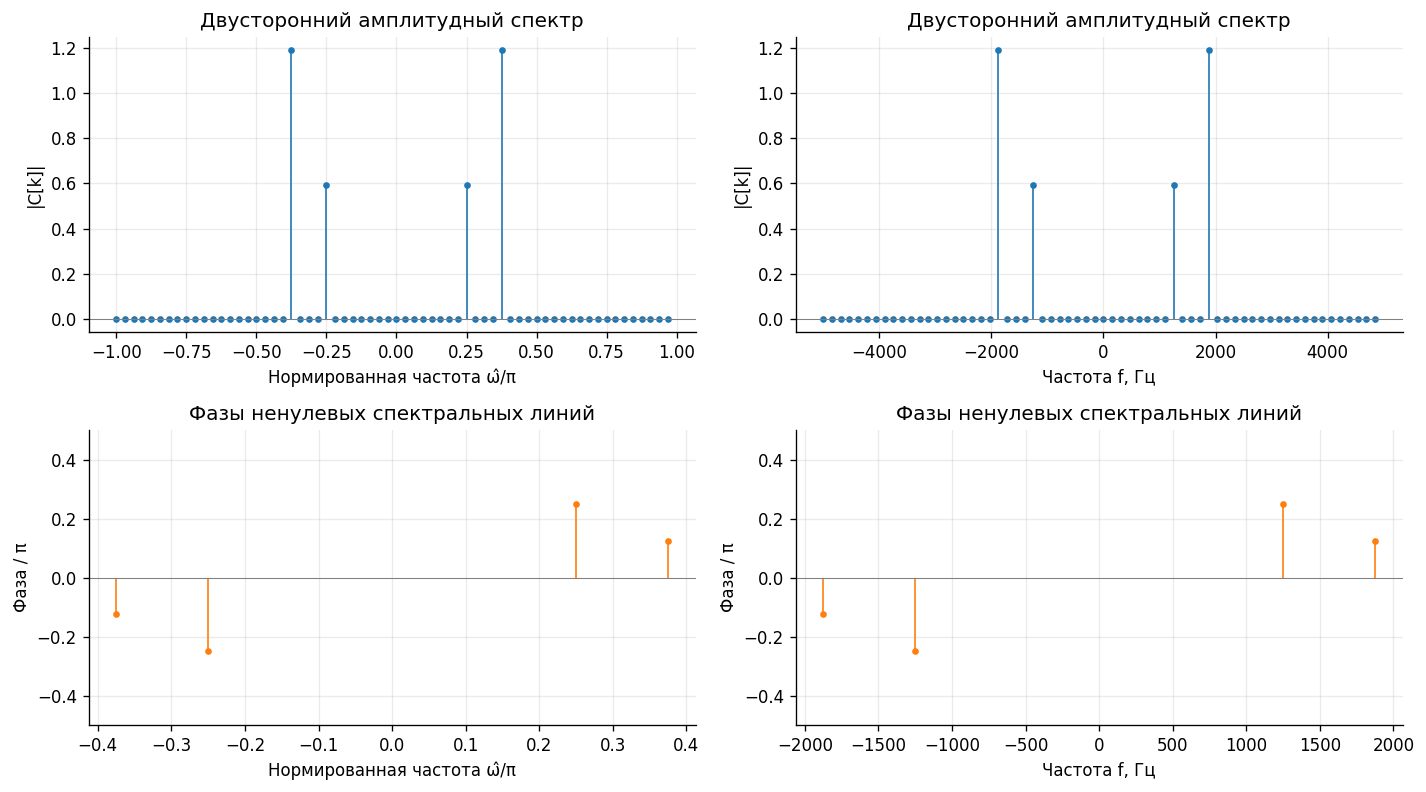

| k | f, Гц | ω̂ | |X[k]| | |C[k]| | Фаза |
| --- | --- | --- | --- | --- | --- |
| -12 | -1875 | -0.375π | 76.16000 | 1.19000 | -0.125π |
| -8 | -1250 | -0.250π | 38.08000 | 0.59500 | -0.250π |
| 8 | 1250 | 0.250π | 38.08000 | 0.59500 | 0.250π |
| 12 | 1875 | 0.375π | 76.16000 | 1.19000 | 0.125π |

In [ ]:
k_signed = np.arange(-N//2, N//2)
X_centered = np.fft.fftshift(X)
C_spec = X_centered / N
amplitude = np.abs(C_spec)
freq_centered = k_signed * fs2/N
omega_centered = 2*np.pi*k_signed/N
significant = amplitude > 1e-10 * amplitude.max()
phase_spec = np.full(N, np.nan)
phase_spec[significant] = np.angle(C_spec[significant])

fig, axes = plt.subplots(2, 2, figsize=(12, 6.7))
for ax, abscissa, xlabel in [
    (axes[0, 0], omega_centered/np.pi, 'Нормированная частота ω̂/π'),
    (axes[0, 1], freq_centered, 'Частота f, Гц'),
]:
    stem(ax, abscissa, amplitude)
    ax.set(xlabel=xlabel, ylabel='|C[k]|', title='Двусторонний амплитудный спектр')
for ax, abscissa, xlabel in [
    (axes[1, 0], omega_centered/np.pi, 'Нормированная частота ω̂/π'),
    (axes[1, 1], freq_centered, 'Частота f, Гц'),
]:
    stem(ax, abscissa[significant], phase_spec[significant]/np.pi, color='C1')
    ax.set(xlabel=xlabel, ylabel='Фаза / π', title='Фазы ненулевых спектральных линий', ylim=(-0.5, 0.5))
fig.tight_layout()
plt.show()

rows = []
for i in np.flatnonzero(significant):
    rows.append([int(k_signed[i]), f'{freq_centered[i]:.0f}',
                 f'{omega_centered[i]/np.pi:.3f}π', f'{abs(X_centered[i]):.5f}',
                 f'{amplitude[i]:.5f}', f'{phase_spec[i]/np.pi:.3f}π'])
table(['k', 'f, Гц', 'ω̂', '|X[k]|', '|C[k]|', 'Фаза'], rows)

Линии находятся при $k=\pm8,\pm12$: это ±1250 и ±1875 Гц,
или $\pm0.25\pi$ и $\pm0.375\pi$. Высоты линий — 0.595 и 1.19;
амплитуды косинусов вдвое больше — 1.19 и 2.38.
Фазы положительных гармоник — $\pi/4$ и $\pi/8$, отрицательных — противоположные.
Шаг сетки равен 156.25 Гц. Растекания нет: обе частоты совпадают с узлами ДПФ.

### Часть 2.4. ДПФ конечной последовательности

$$|X[k]|=64|C[k]|.$$

Положения линий совпадают; модуль ДПФ конечного блока в 64 раза больше
амплитудного спектра периодического продолжения.

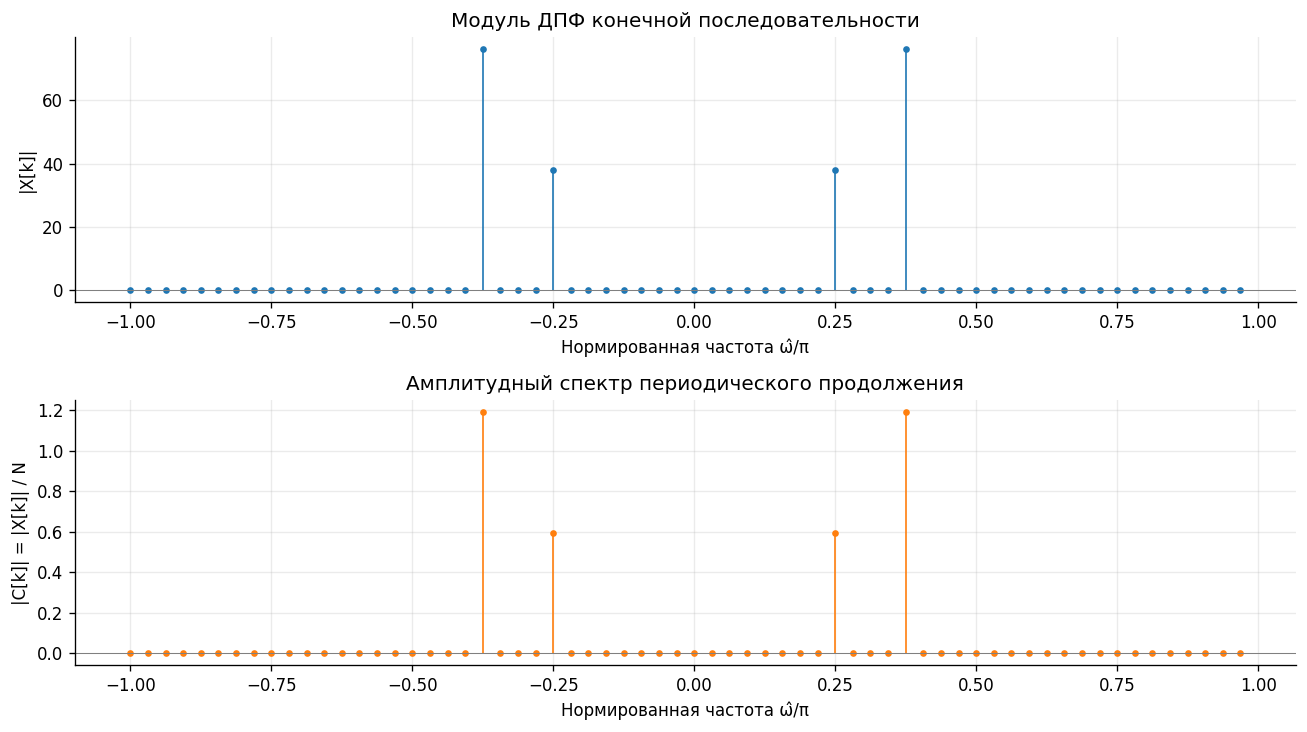

Отношение |X[k]| / |C[k]| на ненулевых линиях: [64. 64. 64. 64.]


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.2))
stem(axes[0], omega_centered/np.pi, np.abs(X_centered))
axes[0].set(xlabel='Нормированная частота ω̂/π', ylabel='|X[k]|', title='Модуль ДПФ конечной последовательности')
stem(axes[1], omega_centered/np.pi, amplitude, color='C1')
axes[1].set(xlabel='Нормированная частота ω̂/π', ylabel='|C[k]| = |X[k]| / N', title='Амплитудный спектр периодического продолжения')
fig.tight_layout()
plt.show()
print('Отношение |X[k]| / |C[k]| на ненулевых линиях:',
      np.abs(X_centered[significant])/amplitude[significant])
assert np.allclose(np.abs(X_centered), N*amplitude, atol=1e-12)

### Часть 2.5. Восстановление аналогового сигнала

$$X_a[k]=\begin{cases}X[64+k],&-32\leq k<0,\\X[k],&0\leq k<32,\end{cases}$$
$$x_r(t)=\frac1{64}\sum_{k=-32}^{31}X_a[k]e^{j2\pi kt/(64T)}.$$

Временная сетка: $t\in[0;63T]$, шаг $T/4=25$ мкс, 253 точки.
Исходный сигнал вычисляется заменой $nT$ на $t$ в формуле пункта 2.1.

Число точек: 253; шаг: 0.00002500 с; конец: 0.0063000 с
Ошибка относительно исходного аналогового сигнала: 4.197e-14
Ошибка в узлах дискретизации: 2.776e-14
Максимальная мнимая часть восстановления: 6.702e-16


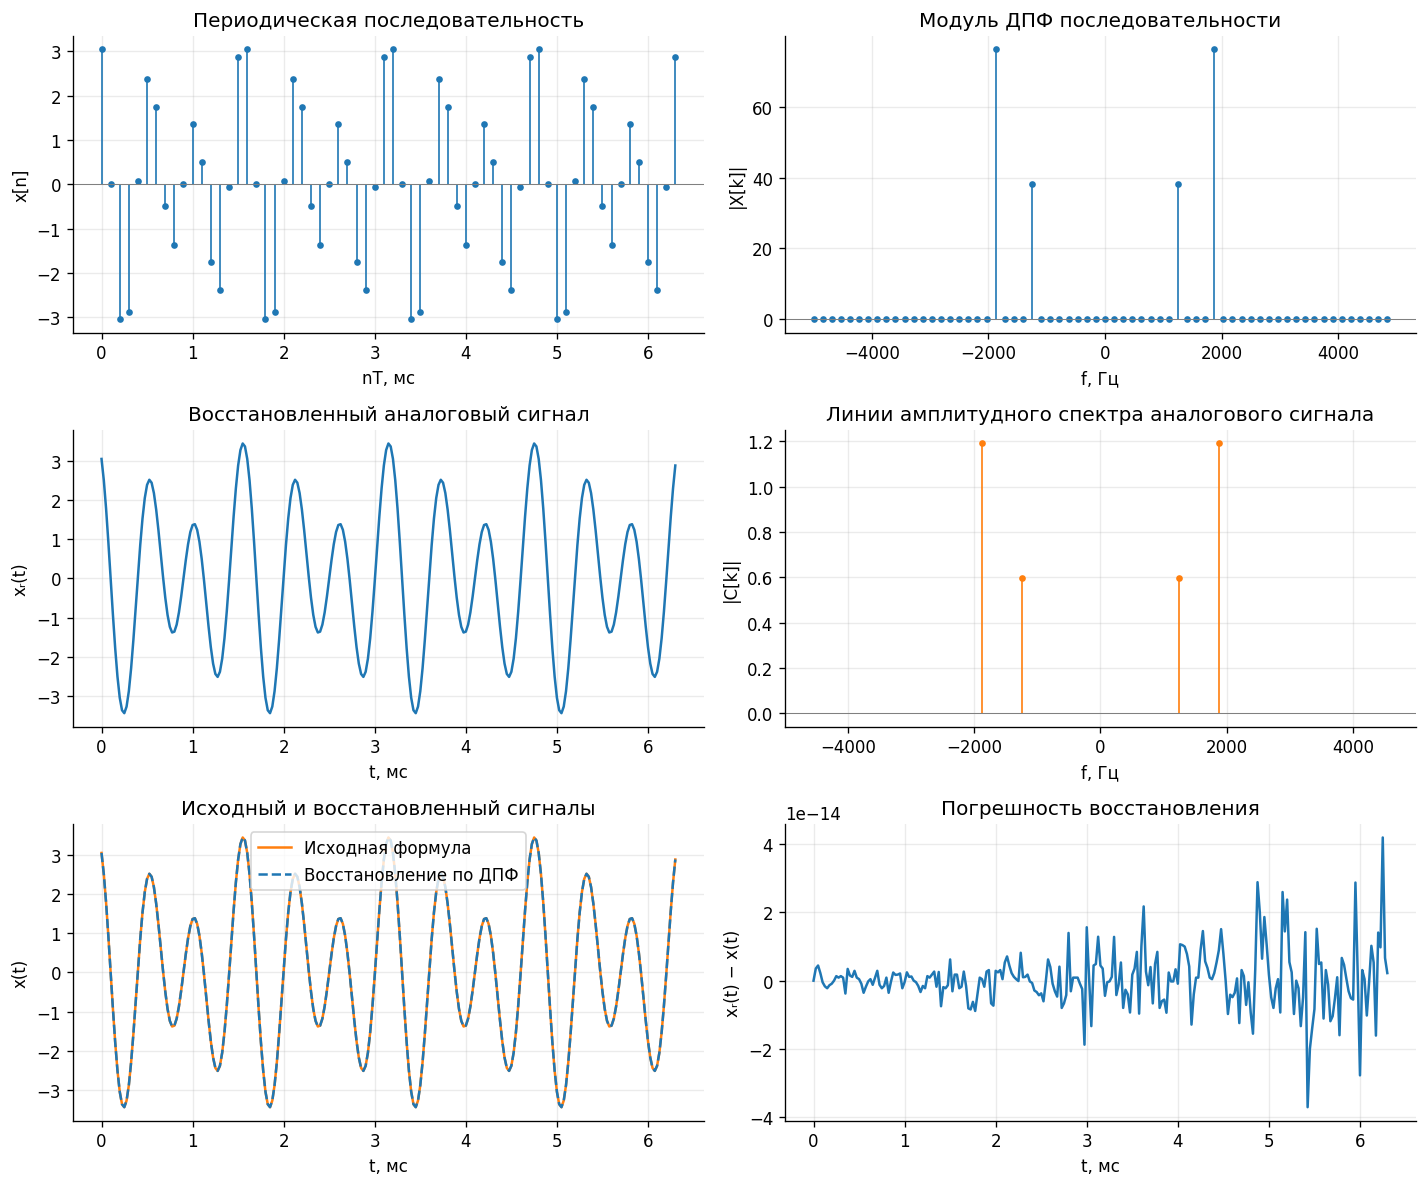

In [ ]:
t_dense = np.arange(4*(N-1)+1) * T/4
# fftshift(X) реализует требуемое соответствие Xa[k] = X[N+k] при k < 0.
reconstruction_matrix = np.exp(2j*np.pi*np.outer(t_dense, k_signed)/(N*T))
x_reconstructed_complex = reconstruction_matrix @ X_centered / N
x_reconstructed = x_reconstructed_complex.real
x_original = A1*np.cos(2*np.pi*f1*t_dense+phi1) + A2*np.cos(2*np.pi*f2*t_dense+phi2)
err_analog = np.max(np.abs(x_reconstructed-x_original))
err_nodes = np.max(np.abs(x_reconstructed[::4]-x))
err_imag = np.max(np.abs(x_reconstructed_complex.imag))
print(f'Число точек: {len(t_dense)}; шаг: {T/4:.8f} с; конец: {t_dense[-1]:.7f} с')
print(f'Ошибка относительно исходного аналогового сигнала: {err_analog:.3e}')
print(f'Ошибка в узлах дискретизации: {err_nodes:.3e}')
print(f'Максимальная мнимая часть восстановления: {err_imag:.3e}')
assert np.allclose(x_reconstructed, x_original, atol=1e-12, rtol=1e-12)
assert np.allclose(x_reconstructed[::4], x, atol=1e-12, rtol=1e-12)

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
stem(axes[0, 0], t_samples*1000, x)
axes[0, 0].set(xlabel='nT, мс', ylabel='x[n]', title='Периодическая последовательность')
stem(axes[0, 1], freq_centered, np.abs(X_centered))
axes[0, 1].set(xlabel='f, Гц', ylabel='|X[k]|', title='Модуль ДПФ последовательности')
axes[1, 0].plot(t_dense*1000, x_reconstructed)
axes[1, 0].set(xlabel='t, мс', ylabel='xᵣ(t)', title='Восстановленный аналоговый сигнал')
stem(axes[1, 1], freq_centered[significant], amplitude[significant], color='C1')
axes[1, 1].set(xlabel='f, Гц', ylabel='|C[k]|', title='Линии амплитудного спектра аналогового сигнала', xlim=(-fs2/2, fs2/2))
axes[2, 0].plot(t_dense*1000, x_original, color='C1', label='Исходная формула')
axes[2, 0].plot(t_dense*1000, x_reconstructed, '--', color='C0', label='Восстановление по ДПФ')
axes[2, 0].set(xlabel='t, мс', ylabel='x(t)', title='Исходный и восстановленный сигналы')
axes[2, 0].legend()
axes[2, 1].plot(t_dense*1000, x_reconstructed-x_original)
axes[2, 1].ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
axes[2, 1].set(xlabel='t, мс', ylabel='xᵣ(t) − x(t)', title='Погрешность восстановления')
fig.tight_layout()
plt.show()

### Часть 2.6. Сравнение сигналов и спектров

Вес каждой линии аналогового спектра равен $|X_a[k]|/64$:
0.595 при ±1250 Гц и 1.19 при ±1875 Гц.
Обе гармоники ниже частоты Найквиста 5000 Гц и попадают в узлы ДПФ,
поэтому исходный и восстановленный сигналы совпадают.
Максимальное численное отличие — около $4.2\cdot10^{-14}$.

### Часть 2.7. Равенство Парсеваля

In [ ]:
energy_time = np.sum(np.abs(x)**2)
energy_freq = np.sum(np.abs(X)**2)/N
energy_theory = N*(A1**2+A2**2)/2
power_time = energy_time/N
power_freq = np.sum(np.abs(C_spec)**2)
err_parseval = abs(energy_time-energy_freq)

table(['Величина', 'Значение'], [
    ['Энергия блока во временной области', f'{energy_time:.4f}'],
    ['Энергия блока по ДПФ', f'{energy_freq:.4f}'],
    ['Теоретическая энергия N(A1² + A2²)/2', f'{energy_theory:.4f}'],
    ['Абсолютная невязка равенства Парсеваля', f'{err_parseval:.3e}'],
    ['Средняя мощность по отсчётам', f'{power_time:.6f}'],
    ['Средняя мощность по коэффициентам C[k]', f'{power_freq:.6f}'],
])
assert np.isclose(energy_time, energy_freq, atol=1e-10, rtol=1e-12)
assert np.isclose(energy_time, energy_theory, atol=1e-10, rtol=1e-12)
assert np.isclose(power_time, power_freq, atol=1e-12, rtol=1e-12)

| Величина | Значение |
| --- | --- |
| Энергия блока во временной области | 226.5760 |
| Энергия блока по ДПФ | 226.5760 |
| Теоретическая энергия N(A1² + A2²)/2 | 226.5760 |
| Абсолютная невязка равенства Парсеваля | 5.684e-14 |
| Средняя мощность по отсчётам | 3.540250 |
| Средняя мощность по коэффициентам C[k] | 3.540250 |

$$E=\frac{64}{2}(1.19^2+2.38^2)=226.576,\qquad P=E/64=3.54025.$$

Равенство Парсеваля подтверждено с невязкой около $5.7\cdot10^{-14}$.
Оно выражает сохранение энергии блока при переходе к частотному представлению;
$P$ — средняя мощность периодической последовательности.

## Выводы

Звено устойчиво, его импульсная характеристика бесконечна и затухает.
Отличие свёртки от рекурсивного расчёта вызвано усечением $h[n]$;
39 отсчётов характеристики достаточны для совпадения реакций в выбранном окне.
АЧХ имеет резонанс около 2.25 кГц и сильнее ослабляет высокие частоты.

ДПФ выявляет гармоники 1250 и 1875 Гц с амплитудами 1.19 и 2.38.
Восстановление отсчётов и аналогового сигнала выполнено с погрешностью округления.
Равенство Парсеваля подтверждено: энергия блока — 226.576, средняя мощность — 3.54025.